# Notebook 1: Top-k truncated sampling for diffusion LMs (model-free harness)

**Run on:** Colab with any GPU (a free **T4** is enough). No model download needed.

This notebook builds and tests everything that does **not** need DiffusionGemma itself:

1. The **full** sampling step, as the DiffusionGemma report describes it (fp32, all 262,144 vocabulary entries).
2. **Top-k truncated** variants of that step, including an exact-normalizer version with tail-entropy bounds.
3. Self-tests that check the math.
4. A **microbenchmark vs. batch size** (time and memory). This is hypothesis H1.
5. **Decision agreement**: do the top-k variants commit the same canvas positions and stop at the same step? (H2, on synthetic logits)
6. A full re-implementation of the report's **Algorithm 1** (entropy-bounded sampler with adaptive stopping), run end to end with a toy denoiser.
7. A replay section to rerun step 5 on **real logits** recorded in Notebook 2.

---

## What "top-k truncated sampling" means here

At every denoising step the model outputs, for each of the 256 canvas slots, a score for every one of the 262,144 tokens. The sampler then does four things per slot:

| Operation | Full version | Why it is expensive |
|---|---|---|
| Probabilities | softmax over all 262,144 tokens, in fp32 | 256 x 262,144 x 4 bytes = **268 MB per sequence**, times batch size |
| Entropy | sum over all tokens of -p log p | reads that whole tensor again |
| Sample a token | categorical draw over all tokens | |
| Self-conditioning mix | probabilities (256 x 262,144) times embedding table (262,144 x d) | about 256 x 262,144 x d multiply-adds per sequence: by far the largest cost |

**Top-k truncation** keeps only the k most likely tokens per slot (k = 64 or 256 instead of 262,144). Almost all probability mass sits in a handful of tokens, so:

- the sample is drawn from k tokens instead of 262,144;
- the mix becomes a weighted sum of just k embedding rows, about 1,000 to 4,000 times cheaper;
- the 268 MB-per-sequence probability tensor never has to exist.

**The catch:** DiffusionGemma's sampler *decides what to commit and when to stop* using entropy. If we just throw the tail away, entropy is underestimated, so the sampler commits too eagerly and stops too early. This notebook shows that effect, and the fix:

- compute the exact normalizer (one log-sum-exp pass over the vocabulary, done in chunks so it needs little memory),
- so the top-k probabilities are exact and the missing tail mass is m = 1 - (sum of top-k probabilities),
- then bound the tail's contribution to entropy:
    - lower bound: -m * log(m)
    - upper bound: -m * log(m) + m * log(V - k)   (tail spread evenly)

The true entropy always lies between `top-k entropy + lower` and `top-k entropy + upper`. Which point in that range best reproduces the full sampler's decisions is an empirical question, and part of the project.

## 1. Setup

In [1]:
print(1)
!nvidia-smi
import torch; print(torch.cuda.is_available())


1
Tue Nov 10 17:51:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+---

In [ ]:
import os
GPU_ID = None   # set to 0 or 1 on a multi-GPU machine; must run before torch is imported
if GPU_ID is not None:
    os.environ['CUDA_VISIBLE_DEVICES'] = str(GPU_ID)

In [2]:
import math, time, gc, glob
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEV, torch.cuda.get_device_name(0) if DEV == 'cuda' else '')

# Keep the reference sampler in true fp32 (the report says sampling runs in full precision).
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# DiffusionGemma-like sizes: canvas and vocabulary from the technical report.
C = 256          # canvas length (slots denoised in parallel)
V = 262_144      # vocabulary size
D = 2048         # hidden size: PLACEHOLDER. Replace with hidden_size printed by Notebook 2.

if DEV == 'cpu':
    V, D = 8192, 256
    print('No GPU: shrinking V and D so the notebook still runs (timings will not be meaningful).')

# Algorithm 1 hyperparameters (Table 2 of the report)
N_MAX, BUDGET, E_STOP, TAU_MAX, TAU_MIN = 48, 0.1, 0.005, 0.8, 0.4

# Logits arrive from the model in bf16 on Ampere+ GPUs; T4 (Turing) has no native bf16, so use fp16 there.
if DEV == 'cuda':
    LOGIT_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    LOGIT_DTYPE = torch.float32
print('logit dtype:', LOGIT_DTYPE)

# Stand-in embedding table in fp32. Real values do not matter for timing; Notebook 2 can supply the real one.
g0 = torch.Generator(device=DEV).manual_seed(0)
E32 = torch.randn(V, D, device=DEV, generator=g0) * 0.02
E_MEAN = E32.mean(0)
print(f'embedding table: {tuple(E32.shape)}  ({E32.numel() * 4 / 2**30:.2f} GB fp32)')

device: cuda Tesla T4
logit dtype: torch.float16
embedding table: (262144, 2048)  (2.00 GB fp32)


## 2. The sampling-step variants

Both functions take logits of shape `[batch, 256, V]` and a temperature, and return:

- `ent`: entropy per slot, `[batch, 256]` (drives commits and stopping)
- `tok`: one sampled token per slot, `[batch, 256]`
- `mix`: the self-conditioning input, `[batch, 256, D]` (probability-weighted sum of embeddings)

The top-k mix uses `F.embedding_bag(..., mode='sum', per_sample_weights=...)`: it gathers k embedding rows per slot and sums them with the probabilities as weights, without ever building a `[256, k, D]` tensor. A fused kernel would do the same thing in one pass.

In [3]:
def chunked_logsumexp(x, tau, chunk=32_768):
    '''log-sum-exp of x / tau over the last dim, in fp32, one vocabulary chunk at a time
    (so a full fp32 copy of the logits never exists).'''
    out = None
    for s in range(0, x.shape[-1], chunk):
        part = torch.logsumexp(x[..., s:s + chunk].float() / tau, dim=-1)
        out = part if out is None else torch.logaddexp(out, part)
    return out


@torch.no_grad()
def sample_full(logits, tau, E, gen=None):
    '''Reference: full-vocabulary fp32 sampling step, as described in the report.'''
    lp = torch.log_softmax(logits.float() / tau, dim=-1)          # [B, C, V] fp32
    p = lp.exp()
    ent = -(p * lp).sum(-1)                                       # [B, C]
    B, Cc, Vv = p.shape
    tok = torch.multinomial(p.view(-1, Vv), 1, generator=gen).view(B, Cc)
    mix = p @ E                                                   # [B, C, D]  <- the big matmul
    return ent, tok, mix


@torch.no_grad()
def sample_topk(logits, tau, E, k=64, tail='hi', mix_mode='drop', E_mean=None, gen=None):
    '''Top-k truncated sampling step.

    tail (entropy used for commit and stop decisions):
        'renorm' : renormalize the top-k, ignore the tail          (cheapest, biased low)
        'none'   : exact top-k probabilities, tail ignored          (biased low)
        'lo'     : exact top-k entropy + lower tail bound  -m log m
        'hi'     : exact top-k entropy + upper tail bound  -m log m + m log(V - k)
        'mid'    : midpoint of the two bounds
    mix_mode (self-conditioning vector):
        'drop'   : sum over top-k of p * E   (tail mass dropped)
        'renorm' : same with renormalized top-k probabilities
        'mean'   : 'drop' + tail_mass * mean embedding
    '''
    Vv = logits.shape[-1]
    vals, idx = torch.topk(logits, k, dim=-1)                     # [B, C, k]
    vals = vals.float() / tau
    if tail == 'renorm':
        lq = torch.log_softmax(vals, dim=-1)
        p_k = lq.exp()
        ent = -(p_k * lq).sum(-1)
        m = torch.zeros_like(ent)
    else:
        lse = chunked_logsumexp(logits, tau)                      # exact normalizer, [B, C]
        lp_k = vals - lse.unsqueeze(-1)
        p_k = lp_k.exp()                                          # exact top-k probabilities
        h_top = -(p_k * lp_k).sum(-1)
        m = (1.0 - p_k.sum(-1)).clamp(0.0, 1.0)                   # tail mass
        tail_lo = -m * torch.log(m.clamp_min(1e-30))
        tail_span = m * math.log(Vv - k) if Vv > k else torch.zeros_like(m)
        if tail == 'none':
            ent = h_top
        elif tail == 'lo':
            ent = h_top + tail_lo
        elif tail == 'hi':
            ent = h_top + tail_lo + tail_span
        elif tail == 'mid':
            ent = h_top + tail_lo + 0.5 * tail_span
        else:
            raise ValueError(tail)

    B, Cc, _ = p_k.shape
    pick = torch.multinomial(p_k.reshape(-1, k), 1, generator=gen).view(B, Cc)   # draws from the top-k only
    tok = torch.gather(idx, -1, pick.unsqueeze(-1)).squeeze(-1)

    w = p_k / p_k.sum(-1, keepdim=True) if mix_mode == 'renorm' else p_k
    mix = F.embedding_bag(idx.reshape(-1, k), E, per_sample_weights=w.reshape(-1, k).contiguous(),
                          mode='sum').view(B, Cc, -1)
    if mix_mode == 'mean':
        mix = mix + m.unsqueeze(-1) * (E_mean if E_mean is not None else E.mean(0))
    return ent, tok, mix

## 3. Self-tests

Two checks on a small vocabulary: with k = V there is no tail, so the exact variant must match the reference; for smaller k the true entropy must sit between the lower and upper bounds.

In [4]:
torch.manual_seed(0)
Vt, Dt = 4096, 64
Lt = torch.randn(2, 8, Vt, device=DEV) * 3
Et = torch.randn(Vt, Dt, device=DEV)
e_ref, _, mix_ref = sample_full(Lt, 0.7, Et)

e_k, _, mix_k = sample_topk(Lt, 0.7, Et, k=Vt, tail='lo')
assert torch.allclose(e_ref, e_k, atol=1e-3), (e_ref - e_k).abs().max()
assert torch.allclose(mix_ref, mix_k, atol=1e-3), (mix_ref - mix_k).abs().max()

for k in [16, 64, 256]:
    lo = sample_topk(Lt, 0.7, Et, k=k, tail='lo')[0]
    hi = sample_topk(Lt, 0.7, Et, k=k, tail='hi')[0]
    assert (lo <= e_ref + 1e-3).all() and (e_ref <= hi + 1e-3).all()
    print(f'k={k:4d}  true entropy - lower bound: {(e_ref - lo).mean():.4f}   upper bound - true: {(hi - e_ref).mean():.4f}')
print('self-tests passed')

k=  16  true entropy - lower bound: 0.7836   upper bound - true: 0.5302
k=  64  true entropy - lower bound: 0.2894   upper bound - true: 0.1335
k= 256  true entropy - lower bound: 0.0570   upper bound - true: 0.0165
self-tests passed


## 4. Microbenchmark: sampling-step cost vs. batch size (H1)

Times one sampling step on random logits shaped like DiffusionGemma's (`[batch, 256, 262144]`). Batches that run out of memory are recorded as missing: that memory wall is itself a result.

`full (optimized)` is version B: the same full-vocabulary math, compiled and with a tensor-core mix. **The comparison that matters is top-k vs. `full (optimized)`**, so any gain is attributable to computing fewer tokens. On a T4 expect the full variants to run out of memory around batch 8 to 16; on an A100 or L40S, rerun with larger batches.

In [5]:
def bench(fn, logits, reps=10, warmup=3):
    '''Median time in ms and peak extra GPU memory in GB for fn(logits).'''
    for _ in range(warmup):
        fn(logits)
    if DEV != 'cuda':
        ts = []
        for _ in range(reps):
            t0 = time.perf_counter(); fn(logits); ts.append((time.perf_counter() - t0) * 1e3)
        return float(torch.tensor(ts).median()), float('nan')
    torch.cuda.synchronize()
    base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    ts = []
    for _ in range(reps):
        start.record(); fn(logits); end.record()
        torch.cuda.synchronize(); ts.append(start.elapsed_time(end))
    peak = (torch.cuda.max_memory_allocated() - base) / 2**30
    return float(torch.tensor(ts).median()), peak

TAU_BENCH = 0.6
# Version B: the best full-vocabulary sampler without the top-k idea (compiled, low-precision tensor-core mix)
MIX_DTYPE = (torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16) if DEV == 'cuda' else torch.float32
E_FAST = E32.to(MIX_DTYPE)
def _full_fast(L, tau):
    lp = torch.log_softmax(L.float() / tau, dim=-1)
    p = lp.exp()
    ent = -(p * lp).sum(-1)
    tok = torch.multinomial(p.view(-1, p.shape[-1]), 1)
    return ent, tok, p.to(MIX_DTYPE) @ E_FAST
try:
    full_fast = torch.compile(_full_fast)
    full_fast(torch.randn(1, C, V, device=DEV, dtype=LOGIT_DTYPE), 0.6)
except Exception as ex:
    print('torch.compile unavailable, using eager version B:', type(ex).__name__)
    full_fast = _full_fast

variants = {
    'full (fp32)':      lambda L: sample_full(L, TAU_BENCH, E32),
    'full (optimized)': lambda L: full_fast(L, TAU_BENCH),
    'top-k 64, hi':     lambda L: sample_topk(L, TAU_BENCH, E32, k=64, tail='hi'),
    'top-k 256, hi':    lambda L: sample_topk(L, TAU_BENCH, E32, k=256, tail='hi'),
    'top-k 64, renorm': lambda L: sample_topk(L, TAU_BENCH, E32, k=64, tail='renorm'),
}
OOM = (torch.cuda.OutOfMemoryError, RuntimeError)

rows = []
for B in [1, 2, 4, 8, 16, 32]:
    try:
        L = torch.randn(B, C, V, device=DEV, dtype=LOGIT_DTYPE) * 2
    except OOM:
        print(f'batch {B}: logits alone do not fit, stopping'); break
    for name, fn in variants.items():
        try:
            ms, gb = bench(fn, L)
        except OOM:
            ms, gb = float('nan'), float('nan')
        rows.append(dict(batch=B, variant=name, ms=ms, peak_extra_GB=gb))
        if DEV == 'cuda':
            torch.cuda.empty_cache()
    del L; gc.collect()
    if DEV == 'cuda':
        torch.cuda.empty_cache()

bench_df = pd.DataFrame(rows)
display(bench_df.pivot(index='batch', columns='variant', values='ms').round(2))
display(bench_df.pivot(index='batch', columns='variant', values='peak_extra_GB').round(2))

W1110 17:55:26.761000 2197 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


variant,full (fp32),full (optimized),"top-k 256, hi","top-k 64, hi","top-k 64, renorm"
batch,,,,,
1,88.85,20.01,17.45,15.55,4.64
2,166.47,40.51,34.44,30.68,9.15
4,332.43,80.75,68.40,60.69,18.88
8,769.57,179.31,139.72,122.14,38.32
16,NaN,NaN,283.59,248.50,78.84
32,NaN,NaN,574.46,502.68,165.23


variant,full (fp32),full (optimized),"top-k 256, hi","top-k 64, hi","top-k 64, renorm"
batch,,,,,
1,0.75,0.63,0.06,0.06,0.00
2,1.50,1.25,0.13,0.13,0.00
4,3.00,2.50,0.25,0.25,0.01
8,6.00,5.00,0.51,0.50,0.02
16,NaN,NaN,1.01,1.00,0.04
32,NaN,NaN,2.02,2.01,0.08


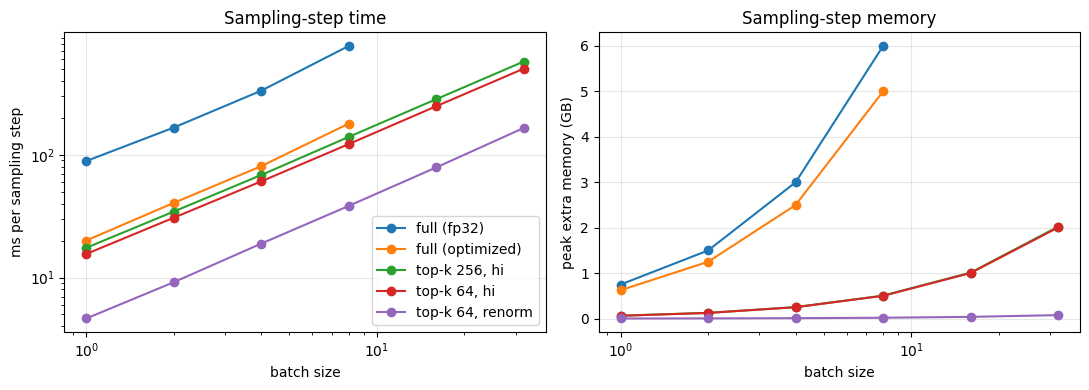

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, grp in bench_df.groupby('variant'):
    axes[0].plot(grp.batch, grp.ms, marker='o', label=name)
    axes[1].plot(grp.batch, grp.peak_extra_GB, marker='o', label=name)
axes[0].set(xscale='log', yscale='log', xlabel='batch size', ylabel='ms per sampling step', title='Sampling-step time')
axes[1].set(xscale='log', xlabel='batch size', ylabel='peak extra memory (GB)', title='Sampling-step memory')
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

Where does the full step's time go? This splits it into its three parts at batch 1.

In [7]:
L1 = torch.randn(1, C, V, device=DEV, dtype=LOGIT_DTYPE) * 2
p1 = torch.softmax(L1.float() / TAU_BENCH, dim=-1)
parts = {
    'softmax + entropy':      lambda L: (lambda lp: -(lp.exp() * lp).sum(-1))(torch.log_softmax(L.float() / TAU_BENCH, -1)),
    'categorical sample':     lambda L: torch.multinomial(p1.view(-1, V), 1),
    'self-conditioning mix':  lambda L: p1 @ E32,
    'top-k 64 (whole step)':  lambda L: sample_topk(L, TAU_BENCH, E32, k=64, tail='hi'),
}
for name, fn in parts.items():
    ms, _ = bench(fn, L1)
    print(f'{name:24s} {ms:8.2f} ms')
del L1, p1

softmax + entropy           15.09 ms
categorical sample           7.71 ms
self-conditioning mix       71.53 ms
top-k 64 (whole step)       15.95 ms


## 5. Decision agreement on synthetic logits (H2, first pass)

Speed only matters if the sampler still makes the **same decisions**. On the same logits, compare each top-k variant with the full reference:

- **jaccard**: overlap of the committed-slot sets (1.0 = identical)
- **ent_bias**: average entropy error (negative = underestimated, so the sampler commits too eagerly)
- **stop_agree**: fraction of sequences where both agree on the adaptive-stopping test
- **mix_cos**: cosine similarity of the self-conditioning vectors

Two synthetic tail shapes are used, because the right tail correction depends on the shape:

- `uniform`: one strong token per slot on top of flat noise (the even-tail upper bound is exact here)
- `zipf`: a ranked, heavy tail closer to real language models

Real logits from Notebook 2 settle the question (section 7).

In [8]:
def synth_logits(B, kind, seed=0):
    g = torch.Generator(device=DEV).manual_seed(seed)
    conf = torch.rand(B, C, 1, device=DEV, generator=g) * 14 + 4           # per-slot confidence 4..18
    if kind == 'uniform':
        L = torch.randn(B, C, V, device=DEV, generator=g)
    else:
        ranks = torch.arange(1, V + 1, device=DEV, dtype=torch.float32)
        base = -1.1 * torch.log(ranks)                                      # Zipf-like ranked tail
        perm = torch.randperm(V, device=DEV, generator=g)
        L = base[perm].expand(B, C, V).clone() + 0.3 * torch.randn(B, C, V, device=DEV, generator=g)
    tgt = torch.randint(V, (B, C, 1), device=DEV, generator=g)
    L.scatter_add_(-1, tgt, conf)
    return L.to(LOGIT_DTYPE)


def commit_set(ent, budget=BUDGET):
    '''Algorithm 1 commit rule: accept slots in order of increasing entropy while the entropy of the
    slots accepted before the current one stays within the budget (so at least one slot is accepted).'''
    order = torch.argsort(ent, dim=-1, stable=True)
    e_sorted = ent.gather(-1, order)
    excl = e_sorted.cumsum(-1) - e_sorted
    n_keep = (excl <= budget).sum(-1, keepdim=True)
    pos = torch.arange(ent.shape[-1], device=ent.device).expand_as(order).contiguous()
    rank = torch.empty_like(order).scatter_(-1, order, pos)
    return rank < n_keep


def agreement(L, tau, k, tail, mix_mode='drop'):
    e_ref, _, mix_ref = sample_full(L, tau, E32)
    e_var, _, mix_var = sample_topk(L, tau, E32, k=k, tail=tail, mix_mode=mix_mode, E_mean=E_MEAN)
    U_ref, U_var = commit_set(e_ref), commit_set(e_var)
    inter = (U_ref & U_var).sum(-1).float()
    union = (U_ref | U_var).sum(-1).float().clamp_min(1)
    stop_ref, stop_var = e_ref.mean(-1) <= E_STOP, e_var.mean(-1) <= E_STOP
    return dict(jaccard=(inter / union).mean().item(),
                commits_ref=U_ref.sum(-1).float().mean().item(),
                commits_var=U_var.sum(-1).float().mean().item(),
                ent_bias=(e_var - e_ref).mean().item(),
                ent_abs_err=(e_var - e_ref).abs().mean().item(),
                stop_agree=(stop_ref == stop_var).float().mean().item(),
                mix_cos=F.cosine_similarity(mix_var, mix_ref, dim=-1).mean().item())

rows = []
for kind in ['uniform', 'zipf']:
    L = synth_logits(2, kind)
    for tau in [0.8, 0.4]:
        for k in [16, 64, 256]:
            for tail in ['renorm', 'none', 'lo', 'mid', 'hi']:
                rows.append(dict(tail_shape=kind, tau=tau, k=k, variant=tail, **agreement(L, tau, k, tail)))
    del L
agree_df = pd.DataFrame(rows)
display(agree_df.round(4))

,tail_shape,tau,k,variant,jaccard,commits_ref,commits_var,ent_bias,ent_abs_err,stop_agree,mix_cos
0,uniform,0.8,16,renorm,0.2144,24.5,114.0,-4.7942,4.7942,1.0,0.9022
1,uniform,0.8,16,none,0.3761,24.5,65.0,-5.2596,5.2596,1.0,0.9022
2,uniform,0.8,16,lo,0.6990,24.5,35.0,-5.1663,5.1663,1.0,0.9022
3,uniform,0.8,16,mid,0.8755,24.5,28.0,-2.4135,2.4135,1.0,0.9022
4,uniform,0.8,16,hi,1.0000,24.5,24.5,0.3392,0.3392,1.0,0.9022
5,uniform,0.8,64,renorm,0.2562,24.5,95.5,-4.3561,4.3561,1.0,0.9150
6,uniform,0.8,64,none,0.3820,24.5,64.0,-5.2283,5.2283,1.0,0.9150
7,uniform,0.8,64,lo,0.6990,24.5,35.0,-5.1323,5.1323,1.0,0.9150
8,uniform,0.8,64,mid,0.8755,24.5,28.0,-2.4015,2.4015,1.0,0.9150
9,uniform,0.8,64,hi,1.0000,24.5,24.5,0.3294,0.3294,1.0,0.9150


Which self-conditioning approximation tracks the full mix best? (Here with a random stand-in embedding table; rerun with the real table later.)

In [9]:
rows = []
for kind in ['uniform', 'zipf']:
    L = synth_logits(2, kind, seed=1)
    for k in [64, 256]:
        for mm in ['drop', 'renorm', 'mean']:
            r = agreement(L, 0.6, k, 'lo', mix_mode=mm)
            rows.append(dict(tail_shape=kind, k=k, mix_mode=mm, mix_cos=r['mix_cos']))
    del L
display(pd.DataFrame(rows).pivot_table(index=['tail_shape', 'k'], columns='mix_mode', values='mix_cos').round(4))

mix_mode          drop    mean  renorm
tail_shape k                          
uniform    64   0.9642  0.9685  0.9642
           256  0.9754  0.9789  0.9754
zipf       64   1.0000  1.0000  1.0000
           256  1.0000  1.0000  1.0000

## 6. Algorithm 1, end to end, with a toy denoiser

This re-implements the report's sampler loop exactly (entropy-bounded commits, re-noising uncommitted slots with uniform random tokens, linear temperature 0.8 to 0.4, adaptive stopping when mean entropy is at most 0.005 **and** the argmax canvas did not change, at most 48 steps), with a pluggable sampling function.

The **toy denoiser** stands in for the network: each slot has a hidden target token and a difficulty, and the model becomes more confident as more of the canvas is correct (context), so easy slots commit first and hard ones later. It ignores self-conditioning. It is only for checking the mechanics and how each variant changes the number of steps; real quality must be measured on the real model.

What you should see: variants that **underestimate** entropy (`renorm`, `none`) commit more per step and **stop earlier** than the reference. With the toy's flat noise tail, the `hi` bound matches the reference almost exactly. The toy is forgiving, so accuracy barely moves; in the real model, stopping early can lock in mistakes.

In [11]:
class ToyDenoiser:
    def __init__(self, B, V, seed=0, sigma=1.0):
        self.g = torch.Generator(device=DEV).manual_seed(seed)
        self.V, self.sigma = V, sigma
        self.target = torch.randint(V, (B, C), device=DEV, generator=self.g)
        self.distract = torch.randint(V, (B, C), device=DEV, generator=self.g)
        self.diff = torch.rand(B, C, device=DEV, generator=self.g)       # 0 = easy, 1 = hard
        self.base = math.log(V) - 6.0                                     # calibrated: ~10-20 steps per canvas

    def __call__(self, x, z=None):
        frac = (x == self.target).float().mean(-1, keepdim=True)          # how much context is right
        s = self.base + 12.0 * (1 - self.diff) + 10.0 * frac              # target strength
        L = self.sigma * torch.randn(*x.shape, self.V, device=DEV, generator=self.g)
        L.scatter_add_(-1, self.target.unsqueeze(-1), s.unsqueeze(-1))
        sd = s - 1.0 - 9.0 * (1 - self.diff) - 6.0 * frac                 # a competing token, strong for hard slots
        L.scatter_add_(-1, self.distract.unsqueeze(-1), sd.unsqueeze(-1))
        return L.to(LOGIT_DTYPE)


@torch.no_grad()
def run_algorithm1(denoiser, sample_fn, B, seed=0, n_max=N_MAX, budget=BUDGET, e_stop=E_STOP,
                   tau_max=TAU_MAX, tau_min=TAU_MIN, ffw=None):
    '''Algorithm 1 of the DiffusionGemma report for one canvas, batched.
    denoiser(x, z) -> logits [B, C, V];  sample_fn(logits, tau) -> (entropy, sampled tokens, mix).'''
    g = torch.Generator(device=DEV).manual_seed(seed + 1000)
    Vv = denoiser.V
    x = torch.randint(Vv, (B, C), device=DEV, generator=g)               # canvas starts as uniform noise
    z, prev = None, None
    done = torch.zeros(B, dtype=torch.bool, device=DEV)
    steps = torch.full((B,), n_max, device=DEV)
    final = torch.zeros(B, C, dtype=torch.long, device=DEV)
    commits = []
    for n in range(1, n_max + 1):
        t = 1 - (n - 1) / n_max
        L = denoiser(x, z)
        xhat = L.argmax(-1)
        tau = (tau_max - tau_min) * t + tau_min
        ent, xs, mix = sample_fn(L, tau)
        if n > 1:                                                         # adaptive stopping
            stop = (~done) & (ent.mean(-1) <= e_stop) & (xhat == prev).all(-1)
            final[stop], steps[stop] = xhat[stop], n
            done |= stop
        if done.all():
            break
        prev = xhat
        if n == n_max:
            final[~done] = xhat[~done]
            break
        U = commit_set(ent, budget)                                       # entropy-bounded commits
        commits.append(U.sum(-1).float().mean().item())
        noise = torch.randint(Vv, (B, C), device=DEV, generator=g)
        x = torch.where(U, xs, noise)                                     # re-noise everything else
        z = mix if ffw is None else ffw(mix)
    return final, steps, commits


samplers = {
    'full (reference)': lambda L, tau: sample_full(L, tau, E32),
    'top-k 64 renorm':  lambda L, tau: sample_topk(L, tau, E32, k=64, tail='renorm'),
    'top-k 64 none':    lambda L, tau: sample_topk(L, tau, E32, k=64, tail='none'),
    'top-k 64 lo':      lambda L, tau: sample_topk(L, tau, E32, k=64, tail='lo'),
    'top-k 64 mid':     lambda L, tau: sample_topk(L, tau, E32, k=64, tail='mid'),
    'top-k 64 hi':      lambda L, tau: sample_topk(L, tau, E32, k=64, tail='hi'),
}
B_TOY = 4 if DEV == 'cuda' else 1
rows = []
for name, fn in samplers.items():
    for seed in range(3):
        den = ToyDenoiser(B_TOY, V, seed=seed)
        t0 = time.time()
        final, steps, commits = run_algorithm1(den, fn, B_TOY, seed=seed)
        rows.append(dict(sampler=name, seed=seed, steps=steps.float().mean().item(),
                         tokens_per_forward=C / steps.float().mean().item(),
                         accuracy=(final == den.target).float().mean().item(),
                         seconds=time.time() - t0))
loop_df = pd.DataFrame(rows)
display(loop_df.groupby('sampler')[['steps', 'tokens_per_forward', 'accuracy', 'seconds']].mean().round(3))

,steps,tokens_per_forward,accuracy,seconds
sampler,,,,
full (reference),10.667,24.021,1.0,4.561
top-k 64 hi,10.750,23.848,1.0,1.076
top-k 64 lo,8.083,31.717,1.0,0.848
top-k 64 mid,9.417,27.303,1.0,0.934
top-k 64 none,4.583,55.891,1.0,0.452
top-k 64 renorm,3.583,71.517,1.0,0.170


## 7. Replay real logits (after Notebook 2)

Notebook 2 saves per-step logits captured from DiffusionGemma's output head to `LOGIT_DIR`. This cell reruns the decision-agreement test of section 5 on them. Real tails are neither flat nor exactly Zipf, so this tells you which tail correction and which k to carry into the live sampler.

Notes:
- Keep only tensors whose second dimension is 256 (canvas steps); prompt-encoding calls are skipped.
- The temperature for step n follows the report's schedule. If the hook also caught non-denoising calls, step numbering may be off by one: check the shapes printed in Notebook 2.
- If the model config has a final logit soft-cap, apply `cap * tanh(x / cap)` before replay (Notebook 2 prints it).

In [12]:
LOGIT_DIR = '/content/drive/MyDrive/dgemma_logits'   # or '/content/logits' if you ran Notebook 2 in this runtime
SOFTCAP = None                                       # set from Notebook 2's config printout, if any

files = sorted(glob.glob(f'{LOGIT_DIR}/step_*.pt'))
print(len(files), 'files found')
rows = []
for n, f in enumerate(files, start=1):
    L = torch.load(f).to(DEV)
    if L.dim() != 3 or L.shape[1] != C or L.shape[-1] != V:
        print('skipping', f, tuple(L.shape)); continue
    if SOFTCAP:
        L = (SOFTCAP * torch.tanh(L.float() / SOFTCAP)).to(LOGIT_DTYPE)
    tau = (TAU_MAX - TAU_MIN) * (1 - (n - 1) / N_MAX) + TAU_MIN
    for k in [16, 64, 256, 1024]:
        for tail in ['renorm', 'none', 'lo', 'mid', 'hi']:
            rows.append(dict(step=n, tau=round(tau, 3), k=k, variant=tail, **agreement(L, tau, k, tail)))
    del L
if rows:
    real_df = pd.DataFrame(rows)
    display(real_df.groupby(['k', 'variant'])[['jaccard', 'ent_bias', 'stop_agree', 'mix_cos']].mean().round(4))

0 files found
